# **Set Seed**

In [40]:
import random
import numpy as np
import tensorflow as tf
import os

SEED = 123

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)

set_seed(SEED)

In [2]:
import os
import shutil

# Source dataset paths
DATASET_PATHS = [
    "/kaggle/input/datasets/waseemalastal/breakhis-breast-cancer-histopathological-dataset/BreakHis - Breast Cancer Histopathological Database/dataset_cancer_v1/dataset_cancer_v1/classificacao_binaria/100X",
    "/kaggle/input/datasets/waseemalastal/breakhis-breast-cancer-histopathological-dataset/BreakHis - Breast Cancer Histopathological Database/dataset_cancer_v1/dataset_cancer_v1/classificacao_binaria/200X",
    "/kaggle/input/datasets/waseemalastal/breakhis-breast-cancer-histopathological-dataset/BreakHis - Breast Cancer Histopathological Database/dataset_cancer_v1/dataset_cancer_v1/classificacao_binaria/400X",
    "/kaggle/input/datasets/waseemalastal/breakhis-breast-cancer-histopathological-dataset/BreakHis - Breast Cancer Histopathological Database/dataset_cancer_v1/dataset_cancer_v1/classificacao_binaria/40X"
]

# Output path
OUTPUT_PATH = "/kaggle/working/train"

classes = ["benign", "malignant"]

os.makedirs(OUTPUT_PATH, exist_ok=True)

for cls in classes:
    dst_folder = os.path.join(OUTPUT_PATH, cls.replace(" ", "_"))
    os.makedirs(dst_folder, exist_ok=True)

    total_count = 0

    # Loop through all dataset splits
    for dataset_path in DATASET_PATHS:
        src_folder = os.path.join(dataset_path, cls)

        if not os.path.exists(src_folder):
            continue

        images = [
            f for f in os.listdir(src_folder)
            if f.lower().endswith(('.jpg', '.jpeg', '.png'))
        ]

        for img in images:
            src_path = os.path.join(src_folder, img)

            # Avoid overwriting same filename
            new_name = f"{os.path.basename(dataset_path)}_{img}"
            dst_path = os.path.join(dst_folder, new_name)

            shutil.copy2(src_path, dst_path)

        total_count += len(images)

    print(f"Class {cls}: {total_count} images copied.")

print("All train + test + validation images merged into one train folder.")

Class benign: 2480 images copied.
Class malignant: 5429 images copied.
All train + test + validation images merged into one train folder.


In [3]:
train_dir = "/kaggle/working/train"

# **Data Visualization**

Classes: ['benign', 'malignant']


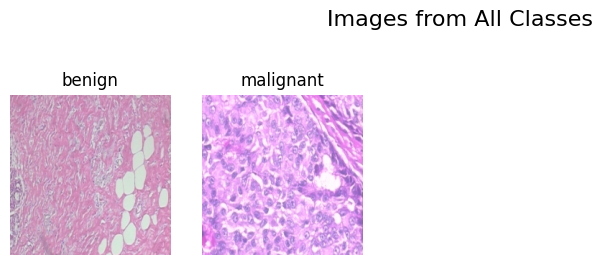

In [4]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import os
import random

classes = os.listdir(train_dir)
print("Classes:", classes)

# Show one random image from each class
plt.figure(figsize=(12, 6))
for i, cls in enumerate(classes):
    cls_path = os.path.join(train_dir, cls)

    # Pick a random image from that class
    img_name = random.choice(os.listdir(cls_path))
    img_path = os.path.join(cls_path, img_name)

    # Read image
    img = mpimg.imread(img_path)

    # Plot
    plt.subplot(2, 5, i+1)  # 2 rows, 5 columns
    plt.imshow(img)
    plt.title(cls)
    plt.axis("off")

plt.suptitle("Images from All Classes", fontsize=16)
plt.show()

/tmp/ipykernel_58/3288521508.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="label", y="count", data=df, palette=he_colors)


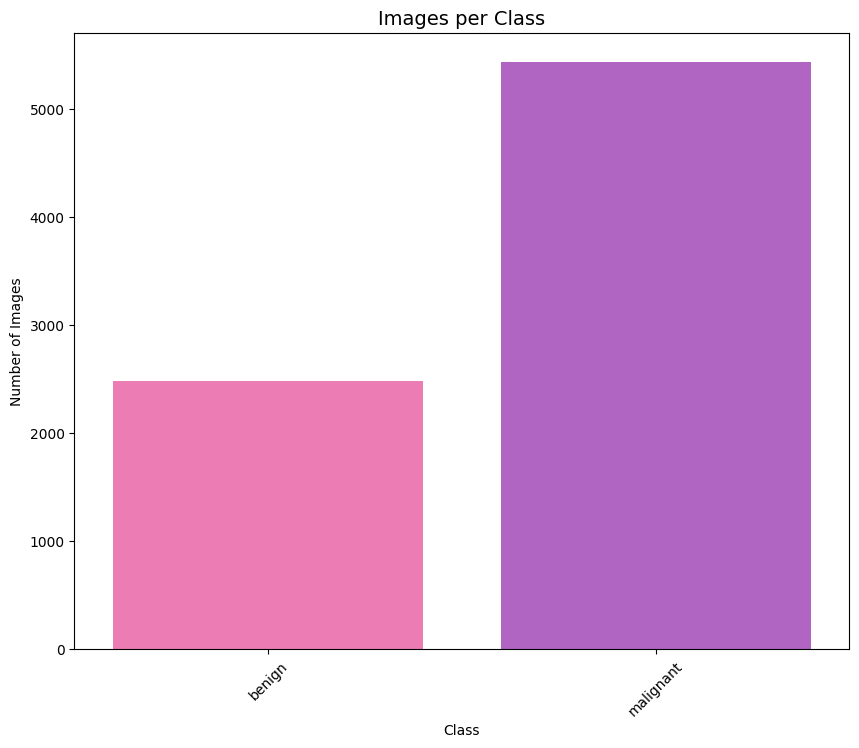

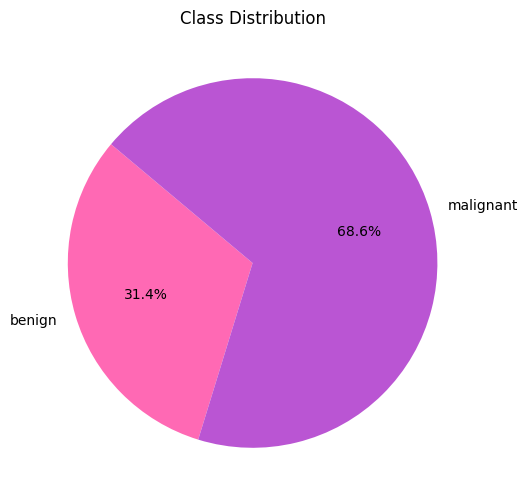

In [5]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Count images per class
df = pd.DataFrame([(cls, len(os.listdir(os.path.join(train_dir, cls))))
                   for cls in os.listdir(train_dir)], columns=["label", "count"])

# H&E-inspired colors (purple/blue + pink)
he_colors = ["#FF69B4", "#BA55D3"]

# Bar chart
plt.figure(figsize=(10, 8))
sns.barplot(x="label", y="count", data=df, palette=he_colors)
plt.xticks(rotation=45)
plt.title("Images per Class", fontsize=14)
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.show()

# Pie chart
df.set_index("label")["count"].plot(kind="pie", autopct="%1.1f%%",
                                    startangle=140, figsize=(6,6),
                                    colors=he_colors)
plt.title("Class Distribution")
plt.ylabel("")
plt.show()

# **Label Encoding**

In [6]:
import os
import re
import pandas as pd
from sklearn.preprocessing import LabelEncoder

# ============================================================
# Build DataFrame
# ============================================================

image_paths, class_names = [], []

for cls in sorted(os.listdir(train_dir)):
    cls_path = os.path.join(train_dir, cls)

    if not os.path.isdir(cls_path):
        continue

    for img in os.listdir(cls_path):
        image_paths.append(os.path.join(cls_path, img))
        class_names.append(cls)

df_all = pd.DataFrame({
    'image_path': image_paths,
    'label': class_names
})


# ============================================================
# Extract BreakHis patient ID
# ============================================================

def extract_patient_id(path):
    filename = os.path.basename(path)

    # Remove magnification prefix
    # Example:
    # 400X_SOB_B_F-14-21998EF-40-001.png

    filename = re.sub(r'^\d+X_', '', filename)

    # Now filename starts with:
    # SOB_B_F-14-21998EF-40-001.png
    # SOB_M_DC-01-1234-40-001.png

    parts = filename.split('-')

    if len(parts) >= 3:
        # Patient ID consists of:
        # F-14-21998EF
        #
        # or:
        # DC-01-1234

        return '-'.join(parts[0].split('_')[-1:] + parts[1:3])

    return None


df_all['patient_id'] = df_all['image_path'].apply(extract_patient_id)


# ============================================================
# Label encoding
# ============================================================

le = LabelEncoder()
df_all['label_num'] = le.fit_transform(df_all['label'])

CLASS_NAMES = list(le.classes_)


# ============================================================
# Verification
# ============================================================

print(f"Total images: {len(df_all)}")
print(f"Classes: {CLASS_NAMES}")

print("\nMissing patient IDs:",
      df_all['patient_id'].isna().sum())

print("\nUnique patients:",
      df_all['patient_id'].nunique())

print("\nPatients per class:")
print(
    df_all.groupby('label')['patient_id']
    .nunique()
)

print("\nExample patient IDs:")
print(df_all[['image_path', 'patient_id', 'label']].head(20))

Total images: 7909
Classes: ['benign', 'malignant']

Missing patient IDs: 0

Unique patients: 82

Patients per class:
label
benign       24
malignant    58
Name: patient_id, dtype: int64

Example patient IDs:
                                           image_path     patient_id   label
0   /kaggle/working/train/benign/40X_SOB_B_A-14-22...   A-14-22549CD  benign
1   /kaggle/working/train/benign/100X_SOB_B_A-14-2...   A-14-22549AB  benign
2   /kaggle/working/train/benign/40X_SOB_B_F-14-29...   F-14-29960AB  benign
3   /kaggle/working/train/benign/40X_SOB_B_TA-14-2...  TA-14-21978AB  benign
4   /kaggle/working/train/benign/100X_SOB_B_PT-14-...  PT-14-21998AB  benign
5   /kaggle/working/train/benign/100X_SOB_B_A-14-2...   A-14-22549AB  benign
6   /kaggle/working/train/benign/100X_SOB_B_F-14-2...   F-14-23060AB  benign
7   /kaggle/working/train/benign/400X_SOB_B_A-14-2...    A-14-22549G  benign
8   /kaggle/working/train/benign/200X_SOB_B_TA-14-...    TA-14-13200  benign
9   /kaggle/working/t

# **Train-Test-Split(Patient Level)**

In [39]:
import os
import numpy as np
import pandas as pd


SEED = 123
TARGET = 500


# ============================================================
# 1. ONE ROW PER PATIENT
# ============================================================

patient_df = (
    df_all[['patient_id', 'label']]
    .drop_duplicates()
    .sort_values(['label', 'patient_id'])
    .reset_index(drop=True)
)

print("=" * 60)
print("PATIENT INFORMATION")
print("=" * 60)

print(f"\nTotal patients: {len(patient_df)}")

print("\nPatients per class:")
print(patient_df['label'].value_counts())


# ============================================================
# 2. COUNT IMAGES PER PATIENT
# ============================================================

patient_counts = (
    df_all
    .groupby(['patient_id', 'label'])
    .size()
    .reset_index(name='image_count')
)

print("\nImages per patient:")
print(patient_counts.head())


# ============================================================
# 3. EXACT DISJOINT SUBSET SEARCH
# ============================================================

def find_two_exact_groups(patient_counts, target=500):
    """
    Find TWO DISJOINT groups of patients such that:

        Group 1 = exactly target images
        Group 2 = exactly target images

    Patients are never split.

    Returns:
        group1_ids, group2_ids

    Raises:
        ValueError if exact solution does not exist.
    """

    patients = patient_counts[['patient_id', 'image_count']].reset_index(drop=True)
    n = len(patients)

    # --------------------------------------------------------
    # State:
    # (validation_total, test_total)
    #
    # For every patient we can:
    #   0 -> leave in training
    #   1 -> validation
    #   2 -> test
    #
    # We only keep totals <= target.
    # --------------------------------------------------------

    states = {(0, 0): None}

    # To reconstruct the solution
    parents = []

    for i in range(n):

        patient_id = patients.loc[i, 'patient_id']
        count = int(patients.loc[i, 'image_count'])

        new_states = dict(states)
        parent_info = {}

        for state in states:

            val_total, test_total = state

            # ------------------------------------------------
            # Put patient into VALIDATION
            # ------------------------------------------------
            new_val = val_total + count

            if new_val <= target:
                new_state = (new_val, test_total)

                if new_state not in new_states:
                    new_states[new_state] = state
                    parent_info[new_state] = (state, 1)

            # ------------------------------------------------
            # Put patient into TEST
            # ------------------------------------------------
            new_test = test_total + count

            if new_test <= target:
                new_state = (val_total, new_test)

                if new_state not in new_states:
                    new_states[new_state] = state
                    parent_info[new_state] = (state, 2)

        states = new_states
        parents.append(parent_info)

        # ----------------------------------------------------
        # Exact solution found
        # ----------------------------------------------------
        if (target, target) in states:
            break

    # ========================================================
    # CHECK WHETHER EXACT SOLUTION EXISTS
    # ========================================================

    if (target, target) not in states:
        raise ValueError(
            f"\nNo exact patient-level solution exists "
            f"for {target} images per class."
        )

    # ========================================================
    # RECONSTRUCT SELECTED PATIENTS
    # ========================================================

    val_ids = []
    test_ids = []

    current_state = (target, target)

    for i in range(len(parents) - 1, -1, -1):

        parent_info = parents[i]

        if current_state in parent_info:

            previous_state, assignment = parent_info[current_state]
            patient_id = patients.loc[i, 'patient_id']

            if assignment == 1:
                val_ids.append(patient_id)
            elif assignment == 2:
                test_ids.append(patient_id)

            current_state = previous_state

    val_ids.reverse()
    test_ids.reverse()

    return val_ids, test_ids


# ============================================================
# 4. FIND EXACT 500+500 FOR EACH CLASS
# ============================================================

all_val_ids = []
all_test_ids = []

for label in sorted(patient_counts['label'].unique()):

    print("\n" + "=" * 60)
    print(f"SEARCHING EXACT SPLIT FOR: {label.upper()}")
    print("=" * 60)

    class_patients = patient_counts[patient_counts['label'] == label].copy()

    val_ids, test_ids = find_two_exact_groups(class_patients, target=TARGET)

    all_val_ids.extend(val_ids)
    all_test_ids.extend(test_ids)

    print(f"\nValidation {label}: {len(val_ids)} patients")
    print(f"Test {label}: {len(test_ids)} patients")


# ============================================================
# 5. CREATE PATIENT SPLITS
# ============================================================

val_patients = patient_df[patient_df['patient_id'].isin(all_val_ids)].copy()
test_patients = patient_df[patient_df['patient_id'].isin(all_test_ids)].copy()
train_patients = patient_df[
    ~patient_df['patient_id'].isin(all_val_ids + all_test_ids)
].copy()


# ============================================================
# 6. ASSIGN ALL IMAGES BY PATIENT
# ============================================================

train_df = df_all[df_all['patient_id'].isin(train_patients['patient_id'])].copy()
val_df = df_all[df_all['patient_id'].isin(val_patients['patient_id'])].copy()
test_df = df_all[df_all['patient_id'].isin(test_patients['patient_id'])].copy()


# ============================================================
# 7. SPLIT SUMMARY
# ============================================================

print("\n" + "=" * 60)
print("FINAL PATIENT-LEVEL SPLIT")
print("=" * 60)

print("\nTrain:")
print(f"  Images   : {len(train_df)}")
print(f"  Patients : {train_df['patient_id'].nunique()}")

print("\nValidation:")
print(f"  Images   : {len(val_df)}")
print(f"  Patients : {val_df['patient_id'].nunique()}")

print("\nTest:")
print(f"  Images   : {len(test_df)}")
print(f"  Patients : {test_df['patient_id'].nunique()}")


# ============================================================
# 8. CLASS DISTRIBUTION
# ============================================================

print("\n" + "=" * 60)
print("CLASS DISTRIBUTION")
print("=" * 60)

print("\nTrain:")
print(train_df['label'].value_counts())

print("\nValidation:")
print(val_df['label'].value_counts())

print("\nTest:")
print(test_df['label'].value_counts())


# ============================================================
# 9. PATIENT DISTRIBUTION
# ============================================================

print("\n" + "=" * 60)
print("PATIENT DISTRIBUTION BY CLASS")
print("=" * 60)

print("\nTrain:")
print(train_patients['label'].value_counts())

print("\nValidation:")
print(val_patients['label'].value_counts())

print("\nTest:")
print(test_patients['label'].value_counts())


# ============================================================
# 10. EXACT TARGET ASSERTIONS
# ============================================================

print("\n" + "=" * 60)
print("EXACT 500-IMAGE CHECK")
print("=" * 60)

val_counts = val_df['label'].value_counts().to_dict()
test_counts = test_df['label'].value_counts().to_dict()

assert val_counts.get('benign', 0) == 500
assert val_counts.get('malignant', 0) == 500

assert test_counts.get('benign', 0) == 500
assert test_counts.get('malignant', 0) == 500

print("\n✓ Validation = exactly 500 benign + 500 malignant")
print("✓ Test       = exactly 500 benign + 500 malignant")
print("✓ Neither split exceeds 500 images per class.")


# ============================================================
# 11. PATIENT LEAKAGE CHECK
# ============================================================

train_ids = set(train_patients['patient_id'])
val_ids = set(val_patients['patient_id'])
test_ids = set(test_patients['patient_id'])

assert len(train_ids & val_ids) == 0
assert len(train_ids & test_ids) == 0
assert len(val_ids & test_ids) == 0

print("\n✓ No patient overlap between splits.")


# ============================================================
# 12. IMAGE ASSIGNMENT CHECK
# ============================================================

total_split_images = len(train_df) + len(val_df) + len(test_df)

assert total_split_images == len(df_all)

print("✓ All images assigned exactly once.")
print(f"\nTotal images: {total_split_images}")

PATIENT INFORMATION

Total patients: 82

Patients per class:
label
malignant    58
benign       24
Name: count, dtype: int64

Images per patient:
     patient_id      label  image_count
0  A-14-22549AB     benign          121
1  A-14-22549CD     benign          132
2   A-14-22549G     benign          130
3  A-14-29960CD     benign           61
4   DC-14-10926  malignant           39

SEARCHING EXACT SPLIT FOR: BENIGN

Validation benign: 4 patients
Test benign: 5 patients

SEARCHING EXACT SPLIT FOR: MALIGNANT

Validation malignant: 5 patients
Test malignant: 5 patients

FINAL PATIENT-LEVEL SPLIT

Train:
  Images   : 5909
  Patients : 63

Validation:
  Images   : 1000
  Patients : 9

Test:
  Images   : 1000
  Patients : 10

CLASS DISTRIBUTION

Train:
label
malignant    4429
benign       1480
Name: count, dtype: int64

Validation:
label
benign       500
malignant    500
Name: count, dtype: int64

Test:
label
benign       500
malignant    500
Name: count, dtype: int64

PATIENT DISTRIBUTION

In [8]:
print(train_df['label_num'].value_counts())

label_num
1    4429
0    1480
Name: count, dtype: int64


# **Create folders for training augmentation**

In [9]:
train_dir_aug = "train_aug"  # folder for augmented training images
os.makedirs(train_dir_aug, exist_ok=True)

for cls in train_df["label"].unique():
    os.makedirs(os.path.join(train_dir_aug, cls), exist_ok=True)

# **Augmentation (Oversampling)**

In [15]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from PIL import Image
import numpy as np
import os

datagen = ImageDataGenerator(
    rotation_range=15,
    width_shift_range=0.05,
    height_shift_range=0.05,
    shear_range=0.05,
    zoom_range=0.1,
    horizontal_flip=True,
    fill_mode='nearest'
)

target_count = 4400  # desired max images per class

for cls in train_df["label"].unique():
    cls_train_images = train_df[train_df['label'] == cls]["image_path"].tolist()
    cls_aug_path = os.path.join(train_dir_aug, cls)

    # Copy original images to augmented folder
    for img_path in cls_train_images:
        img_name = os.path.basename(img_path)
        dest_path = os.path.join(cls_aug_path, img_name)
        if not os.path.exists(dest_path):
            Image.open(img_path).convert("RGB").save(dest_path)

    # Now calculate current count AFTER copying originals
    current_count = len(os.listdir(cls_aug_path))

    needed = target_count - current_count
    if needed <= 0:
        print(f"Skipping {cls}: {current_count} images already present.")
        continue

    print(f"Augmenting {cls}: generating {needed} images...")

    img_index = 0
    cls_aug_images = [os.path.join(cls_aug_path, f) for f in os.listdir(cls_aug_path)]
    for _ in range(needed):
        img_path = cls_aug_images[img_index % len(cls_train_images)]
        img = np.expand_dims(np.array(Image.open(img_path).convert("RGB")), axis=0)
        aug_iter = datagen.flow(img, batch_size=1,
                                save_to_dir=cls_aug_path,
                                save_prefix="aug",
                                save_format="jpg")
        next(aug_iter)
        img_index += 1

# After all classes, print final counts
print("\n✅ Data augmentation completed.\n")
for cls in os.listdir(train_dir_aug):
    count = len(os.listdir(os.path.join(train_dir_aug, cls)))
    print(f"{cls}: {count} images")

Augmenting benign: generating 5 images...
Skipping malignant: 4429 images already present.

✅ Data augmentation completed.

benign: 4400 images
malignant: 4429 images


# **Recreate train_df from augmented folder**

In [16]:
train_image_paths = []
train_labels_num = []

for cls in os.listdir(train_dir_aug):
    cls_path = os.path.join(train_dir_aug, cls)
    for img_name in os.listdir(cls_path):
        train_image_paths.append(os.path.join(cls_path, img_name))
        train_labels_num.append(le.transform([cls])[0])

train_df_aug = pd.DataFrame({
    "image_path": train_image_paths,
    "label_num": train_labels_num
})

print("Class distribution after augmentation:")
print(train_df_aug["label_num"].value_counts())

Class distribution after augmentation:
label_num
1    4429
0    4400
Name: count, dtype: int64


# **Data-Augmentation**

In [17]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.mobilenet import preprocess_input

batch_size = 32
img_size = (224, 224)

# Training augmentation
tr_gen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=30,
    width_shift_range=0.15,
    height_shift_range=0.15,
    zoom_range=0.2,
    horizontal_flip=True,
    vertical_flip=True,
    brightness_range=[0.8, 1.2],
    shear_range=10,
    fill_mode='nearest'
)

# Test/validation generator (no augmentation)
ts_gen = ImageDataGenerator(preprocessing_function=preprocess_input)

# Convert 'label_num' columns to string type for flow_from_dataframe with class_mode='sparse'
train_df_aug['label_num'] = train_df_aug['label_num'].astype(str)
val_df['label_num'] = val_df['label_num'].astype(str)
test_df['label_num'] = test_df['label_num'].astype(str)

train_gen = tr_gen.flow_from_dataframe(train_df_aug, x_col='image_path', y_col='label_num',
                                       target_size=img_size, class_mode='sparse',
                                       color_mode='rgb', shuffle=True, batch_size=batch_size,seed=SEED)

valid_gen = ts_gen.flow_from_dataframe(val_df, x_col='image_path', y_col='label_num',
                                       target_size=img_size, class_mode='sparse',
                                       color_mode='rgb', shuffle=True, batch_size=batch_size,seed=SEED)

test_gen = ts_gen.flow_from_dataframe(test_df, x_col='image_path', y_col='label_num',
                                      target_size=img_size, class_mode='sparse',
                                      color_mode='rgb', shuffle=False, batch_size=batch_size,seed=SEED)

Found 8829 validated image filenames belonging to 2 classes.
Found 1000 validated image filenames belonging to 2 classes.
Found 1000 validated image filenames belonging to 2 classes.


# **Removing Unreadble File**

In [18]:
from PIL import Image
import os

bad_files = []

for filepath in train_gen.filepaths:
    try:
        with Image.open(filepath) as img:
            img.verify()
    except Exception as e:
        bad_files.append((filepath, str(e)))

print(f"Total files: {len(train_gen.filepaths)}")
print(f"Bad files: {len(bad_files)}")

for filepath, error in bad_files:
    print(filepath)
    print(" ->", error)

Total files: 8829
Bad files: 0


In [19]:
from PIL import Image
import os

bad_files = []

for filepath in train_gen.filepaths:
    try:
        with Image.open(filepath) as img:
            img.verify()
    except Exception:
        bad_files.append(filepath)

print(f"Found {len(bad_files)} corrupted/unreadable images.")

for filepath in bad_files:
    print("Removing:", filepath)
    os.remove(filepath)

Found 0 corrupted/unreadable images.


# **MobileNet**

In [20]:
from tensorflow.keras.applications import MobileNet
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense, Dropout, BatchNormalization, GlobalAveragePooling2D
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.optimizers.schedules import CosineDecay

def create_efficientnet_simple(input_shape=(224,224,3), num_classes=2):
    inputs = Input(shape=input_shape)

    # Pretrained  without top layers
    base = MobileNet(weights='imagenet', include_top=False, input_tensor=inputs)

    # Freeze most layers except last 30 for fine-tuning
    for layer in base.layers[:-30]:
        layer.trainable = False

    # Base output
    x = base.output
    x = GlobalAveragePooling2D()(x)

    # Fully connected layers
    x = Dense(512, activation='relu')(x)
    x = BatchNormalization()(x)
    x = Dropout(0.5)(x)

    x = Dense(256, activation='relu')(x)
    x = Dropout(0.4)(x)

    # Output layer
    outputs = Dense(num_classes, activation='softmax')(x)

    return Model(inputs, outputs)


# Learning rate schedule (cosine decay)
lr_schedule = CosineDecay(
    initial_learning_rate=3e-4,  # starting LR
    decay_steps=1000,            # steps for one cycle
    alpha=1e-6                   # final LR fraction
)

# Create and compile model
model = create_efficientnet_simple(num_classes=2)
model.compile(
    optimizer=Adam(learning_rate=lr_schedule),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

/tmp/ipykernel_58/2190541078.py:11: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = MobileNet(weights='imagenet', include_top=False, input_tensor=inputs)
I0000 00:00:1790360082.392462      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1790360082.395268      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


17225924/17225924 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 112, 112, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1_bn (BatchNormalization)   │ (None, 112, 112, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1_relu (ReLU)               │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_1 (DepthwiseConv2D)     │ (None, 112, 112, 32)   │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_1_bn                    │ (None, 112, 112, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_1_relu (ReLU)           │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_1 (Conv2D)              │ (None, 112, 112, 64)   │         2,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_1_bn                    │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_1_relu (ReLU)           │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pad_2 (ZeroPadding2D)      │ (None, 113, 113, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_2 (DepthwiseConv2D)     │ (None, 56, 56, 64)     │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_2_bn                    │ (None, 56, 56, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_2_relu (ReLU)           │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_2 (Conv2D)              │ (None, 56, 56, 128)    │         8,192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_2_bn                    │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_2_relu (ReLU)           │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_3 (DepthwiseConv2D)     │ (None, 56, 56, 128)    │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_3_bn                    │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_3_relu (ReLU)           │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_3 (Conv2D)              │ (None, 56, 56, 128)    │        16,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_3_bn                    │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 3,887,554 (14.83 MB)

 Trainable params: 3,053,314 (11.65 MB)

 Non-trainable params: 834,240 (3.18 MB)

In [21]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

callbacks = [
    EarlyStopping(monitor='val_accuracy', patience=8, restore_best_weights=True, verbose=1),
    ModelCheckpoint("best_model.h5", monitor='val_accuracy', save_best_only=True, verbose=1)
]

history = model.fit(
    train_gen,
    validation_data=valid_gen,
    epochs=30,
    callbacks= callbacks,
    verbose=1
)

Epoch 1/30


2026-09-25 18:15:18.195576: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-25 18:15:18.333616: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
I0000 00:00:1790360123.851674     168 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


270/276 ━━━━━━━━━━━━━━━━━━━━ 2s 405ms/step - accuracy: 0.7848 - loss: 0.5515

2026-09-25 18:17:21.682695: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-25 18:17:21.833434: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-25 18:17:21.972062: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


276/276 ━━━━━━━━━━━━━━━━━━━━ 0s 453ms/step - accuracy: 0.7861 - loss: 0.5484

...


Epoch 1: finished saving model to best_model.h5
276/276 ━━━━━━━━━━━━━━━━━━━━ 161s 505ms/step - accuracy: 0.8468 - loss: 0.4056 - val_accuracy: 0.6060 - val_loss: 1.4268
Epoch 2/30
276/276 ━━━━━━━━━━━━━━━━━━━━ 0s 405ms/step - accuracy: 0.9143 - loss: 0.2181
Epoch 2: val_accuracy improved from 0.60600 to 0.77000, saving model to best_model.h5



Epoch 2: finished saving model to best_model.h5
276/276 ━━━━━━━━━━━━━━━━━━━━ 114s 415ms/step - accuracy: 0.9178 - loss: 0.2127 - val_accuracy: 0.7700 - val_loss: 0.6897
Epoch 3/30
276/276 ━━━━━━━━━━━━━━━━━━━━ 0s 401ms/step - accuracy: 0.9285 - loss: 0.1791
Epoch 3: val_accuracy did not improve from 0.77000
276/276 ━━━━━━━━━━━━━━━━━━━━ 113s 410ms/step - accuracy: 0.9306 - loss: 0.1774 - val_accuracy: 0.7370 - val_loss: 0.7453
Epoch 4/30
276/276 ━━━━━━━━━━━━━━━━━━━━ 0s 403ms/step - accuracy: 0.9428 - loss: 0.1540
Epoch 4: val_accuracy improved from 0.77000 to 0.78600, saving model to best_model.h5



Epoch 4: finished saving model to best_model.h5
276/276 ━━━━━━━━━━━━━━━━━━━━ 114s 412ms/step - accuracy: 0.9435 - loss: 0.1467 - val_accuracy: 0.7860 - val_loss: 0.5879
Epoch 5/30
276/276 ━━━━━━━━━━━━━━━━━━━━ 0s 400ms/step - accuracy: 0.9385 - loss: 0.1605
Epoch 5: val_accuracy did not improve from 0.78600
276/276 ━━━━━━━━━━━━━━━━━━━━ 113s 409ms/step - accuracy: 0.9404 - loss: 0.1474 - val_accuracy: 0.7830 - val_loss: 0.5976
Epoch 6/30
276/276 ━━━━━━━━━━━━━━━━━━━━ 0s 403ms/step - accuracy: 0.9404 - loss: 0.1516
Epoch 6: val_accuracy did not improve from 0.78600
276/276 ━━━━━━━━━━━━━━━━━━━━ 114s 411ms/step - accuracy: 0.9397 - loss: 0.1531 - val_accuracy: 0.7780 - val_loss: 0.6032
Epoch 7/30
276/276 ━━━━━━━━━━━━━━━━━━━━ 0s 397ms/step - accuracy: 0.9363 - loss: 0.1619
Epoch 7: val_accuracy improved from 0.78600 to 0.78900, saving model to best_model.h5



Epoch 7: finished saving model to best_model.h5
276/276 ━━━━━━━━━━━━━━━━━━━━ 112s 407ms/step - accuracy: 0.9411 - loss: 0.1467 - val_accuracy: 0.7890 - val_loss: 0.5761
Epoch 8/30
276/276 ━━━━━━━━━━━━━━━━━━━━ 0s 410ms/step - accuracy: 0.9489 - loss: 0.1357
Epoch 8: val_accuracy did not improve from 0.78900
276/276 ━━━━━━━━━━━━━━━━━━━━ 115s 418ms/step - accuracy: 0.9453 - loss: 0.1436 - val_accuracy: 0.7790 - val_loss: 0.6020
Epoch 9/30
276/276 ━━━━━━━━━━━━━━━━━━━━ 0s 404ms/step - accuracy: 0.9453 - loss: 0.1414
Epoch 9: val_accuracy did not improve from 0.78900
276/276 ━━━━━━━━━━━━━━━━━━━━ 114s 412ms/step - accuracy: 0.9411 - loss: 0.1532 - val_accuracy: 0.7850 - val_loss: 0.5874
Epoch 10/30
276/276 ━━━━━━━━━━━━━━━━━━━━ 0s 400ms/step - accuracy: 0.9374 - loss: 0.1552
Epoch 10: val_accuracy improved from 0.78900 to 0.79000, saving model to best_model.h5



Epoch 10: finished saving model to best_model.h5
276/276 ━━━━━━━━━━━━━━━━━━━━ 113s 409ms/step - accuracy: 0.9413 - loss: 0.1509 - val_accuracy: 0.7900 - val_loss: 0.5705
Epoch 11/30
276/276 ━━━━━━━━━━━━━━━━━━━━ 0s 401ms/step - accuracy: 0.9360 - loss: 0.1581
Epoch 11: val_accuracy did not improve from 0.79000
276/276 ━━━━━━━━━━━━━━━━━━━━ 113s 409ms/step - accuracy: 0.9399 - loss: 0.1517 - val_accuracy: 0.7850 - val_loss: 0.5872
Epoch 12/30
276/276 ━━━━━━━━━━━━━━━━━━━━ 0s 398ms/step - accuracy: 0.9399 - loss: 0.1498
Epoch 12: val_accuracy did not improve from 0.79000
276/276 ━━━━━━━━━━━━━━━━━━━━ 112s 406ms/step - accuracy: 0.9384 - loss: 0.1529 - val_accuracy: 0.7840 - val_loss: 0.5908
Epoch 13/30
276/276 ━━━━━━━━━━━━━━━━━━━━ 0s 397ms/step - accuracy: 0.9405 - loss: 0.1469
Epoch 13: val_accuracy did not improve from 0.79000
276/276 ━━━━━━━━━━━━━━━━━━━━ 112s 405ms/step - accuracy: 0.9405 - loss: 0.1475 - val_accuracy: 0.7820 - val_loss: 0.5976
Epoch 14/30
276/276 ━━━━━━━━━━━━━━━━━━━━ 0s

In [22]:
# Evaluate on the test generator
loss, accuracy = model.evaluate(test_gen, verbose=1)

print(f"Final Test Accuracy: {accuracy*100:.2f}%")
print(f"Final Test Loss: {loss:.4f}")

32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 68ms/step - accuracy: 0.7610 - loss: 0.9142
Final Test Accuracy: 76.10%
Final Test Loss: 0.9142


In [23]:
from tensorflow.keras.models import load_model
model.load_weights('best_model.h5')
best_model = model

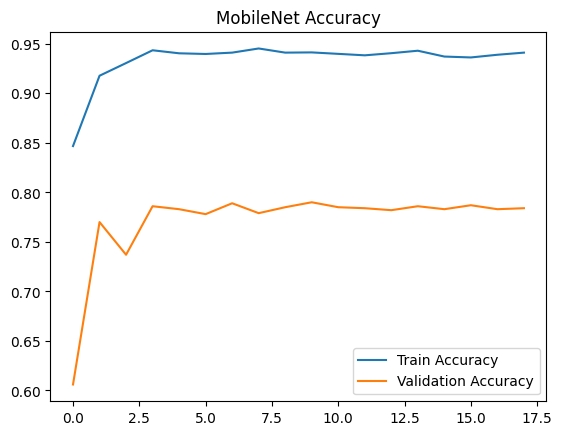

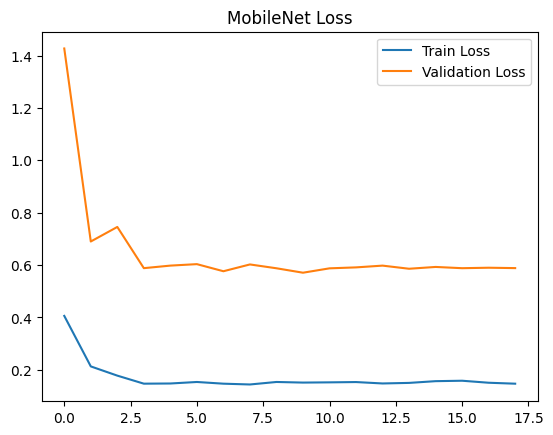

In [24]:
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.legend()
plt.title("MobileNet Accuracy")
plt.show()

plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.legend()
plt.title("MobileNet Loss")
plt.show()

32/32 ━━━━━━━━━━━━━━━━━━━━ 7s 148ms/step

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.53      0.69       500
           1       0.68      0.99      0.81       500

    accuracy                           0.76      1000
   macro avg       0.83      0.76      0.75      1000
weighted avg       0.83      0.76      0.75      1000



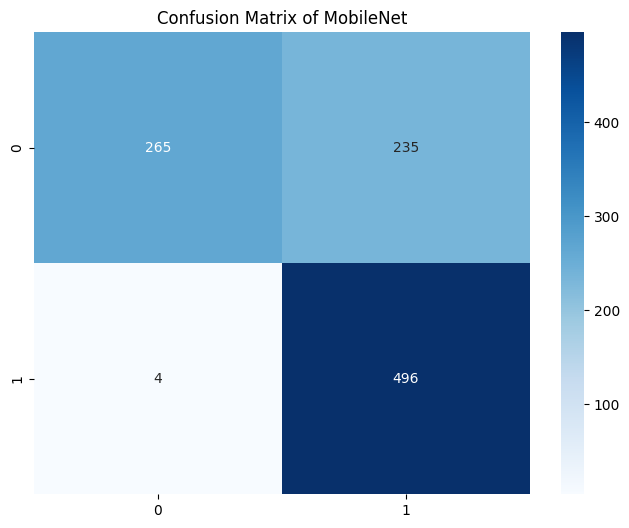

In [25]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# True labels from test generator
y_true = test_gen.classes

# Predictions
y_pred = np.argmax(model.predict(test_gen), axis=1) #argmax finds the index of the largest value in an array

# Classification report
print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=list(test_gen.class_indices.keys())))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=test_gen.class_indices.keys(),
            yticklabels=test_gen.class_indices.keys())
plt.title("Confusion Matrix of MobileNet")
plt.show()

# **AUC-ROC**

In [26]:
y_prob = model.predict(test_gen)

32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 69ms/step


32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 72ms/step


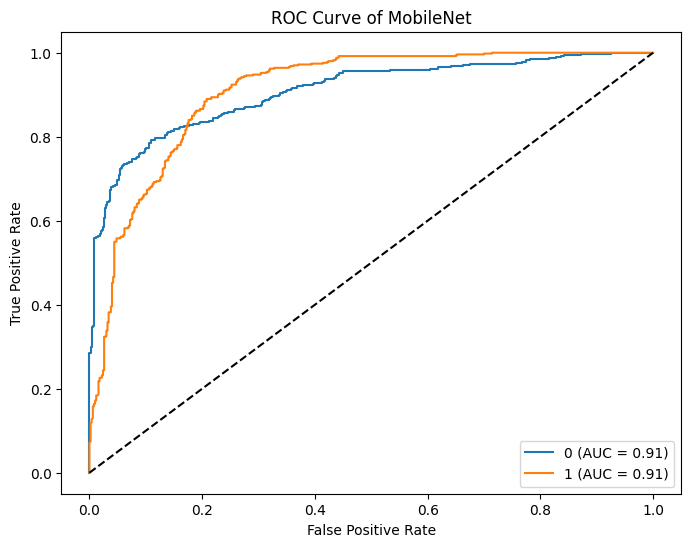

In [27]:
import numpy as np
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt

# Number of classes
class_names = list(test_gen.class_indices.keys())
n_classes = len(class_names)

# True labels
y_true = np.array(test_gen.classes) # Converted to NumPy array here

# Predicted probabilities (softmax outputs)
y_prob = model.predict(test_gen)

# Plot ROC curves
plt.figure(figsize=(8, 6))

for i in range(n_classes):
    # For each class, treat it as the positive class
    # Convert y_true to binary labels (1 if it's class i, 0 otherwise)
    y_true_for_class_i = (y_true == i).astype(int)

    # Use the probabilities for class i
    y_score_for_class_i = y_prob[:, i]

    fpr, tpr, _ = roc_curve(y_true_for_class_i, y_score_for_class_i)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{class_names[i]} (AUC = {roc_auc:.2f})")

# Random chance line
plt.plot([0, 1], [0, 1], 'k--')

plt.title("ROC Curve of MobileNet")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.show()

# **Compute Flops,Measure Inference Time,Memory Consumption**

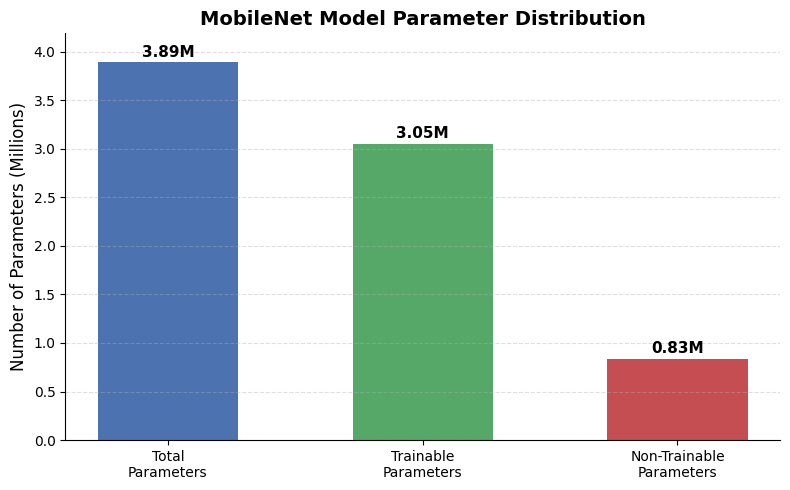

In [28]:
import matplotlib.pyplot as plt
import tensorflow as tf

# Get parameters automatically
total_params = model.count_params()

trainable_params = sum(
    [tf.keras.backend.count_params(w) for w in model.trainable_weights]
)

non_trainable_params = sum(
    [tf.keras.backend.count_params(w) for w in model.non_trainable_weights]
)

# Convert to millions
params = [
    total_params / 1e6,
    trainable_params / 1e6,
    non_trainable_params / 1e6
]

labels = [
    "Total\nParameters",
    "Trainable\nParameters",
    "Non-Trainable\nParameters"
]

# Add colors
colors = ["#4C72B0", "#55A868", "#C44E52"]

plt.figure(figsize=(8, 5))

bars = plt.bar(
    labels,
    params,
    width=0.55,
    color=colors
)

# Add values above bars
for bar, value in zip(bars, params):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.03,
        f"{value:.2f}M",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

plt.ylabel("Number of Parameters (Millions)", fontsize=12)
plt.title(
    "MobileNet Model Parameter Distribution",
    fontsize=14,
    fontweight="bold"
)

plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)

plt.ylim(0, max(params) + 0.3)

plt.tight_layout()
plt.show()

I0000 00:00:1790362514.515029      58 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 2
I0000 00:00:1790362514.515217      58 single_machine.cc:376] Starting new session
I0000 00:00:1790362514.530440      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1790362514.532041      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Instructions for updating:
This API was designed for TensorFlow v1. See https://www.tensorflow.org/guide/migrate for instructions on how to migrate your code to TensorFlow v2.


Instructions for updating:
This API was designed for TensorFlow v1. See https://www.tensorflow.org/guide/migrate for instructions on how to migrate your code to TensorFlow v2.



=========================Options=============================
-max_depth                  10000
-min_bytes                  0
-min_peak_bytes             0
-min_residual_bytes         0
-min_output_bytes           0
-min_micros                 0
-min_accelerator_micros     0
-min_cpu_micros             0
-min_params                 0
-min_float_ops              1
-min_occurrence             0
-step                       -1
-order_by                   float_ops
-account_type_regexes       .*
-start_name_regexes         .*
-trim_name_regexes          
-show_name_regexes          .*
-hide_name_regexes          
-account_displayed_op_only  true
-select                     float_ops
-output                     stdout:

==================Model Analysis Report======================

Doc:
op: The nodes are operation kernel type, such as MatMul, Conv2D. Graph nodes belonging to the same type are aggregated together.
flops: Number of float operations. Note: Please read the implementation for th

2026-09-25 18:55:22.032160: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-25 18:55:22.165321: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


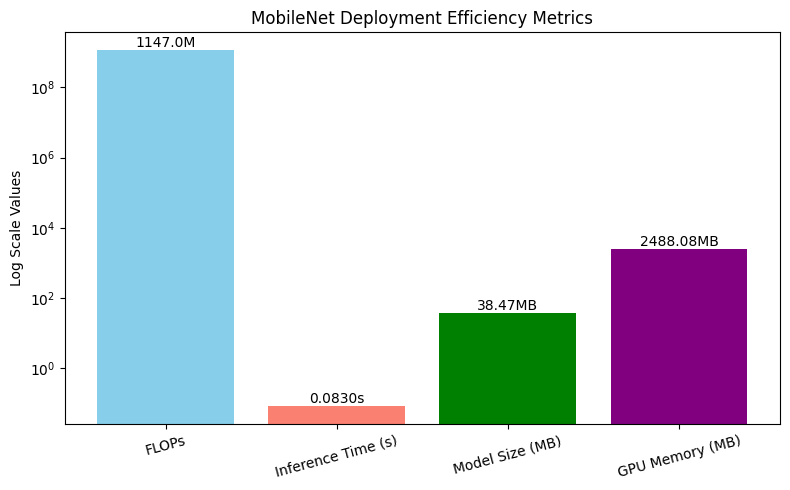

In [29]:
import tensorflow as tf
import time
import numpy as np
import matplotlib.pyplot as plt
import os
from tensorflow.python.framework.convert_to_constants import convert_variables_to_constants_v2


# ============================================================
# 1. FLOPs CALCULATION
# ============================================================
def get_flops(model):
    input_shape = [1] + list(model.input_shape[1:])

    concrete_func = tf.function(lambda x: model(x))
    concrete_func = concrete_func.get_concrete_function(
        tf.TensorSpec(input_shape, model.inputs[0].dtype)
    )

    frozen_func = convert_variables_to_constants_v2(concrete_func)
    graph_def = frozen_func.graph.as_graph_def()

    with tf.Graph().as_default() as graph:
        tf.graph_util.import_graph_def(graph_def, name="")
        run_meta = tf.compat.v1.RunMetadata()
        opts = tf.compat.v1.profiler.ProfileOptionBuilder.float_operation()
        flops = tf.compat.v1.profiler.profile(
            graph=graph,
            run_meta=run_meta,
            cmd='op',
            options=opts
        )
        return flops.total_float_ops


flops = get_flops(model)


# ============================================================
# 2. INFERENCE TIME
# ============================================================
x_sample = np.random.rand(1, 224, 224, 3).astype(np.float32)

_ = model.predict(x_sample, verbose=0)  # warm-up

start = time.time()
_ = model.predict(x_sample, verbose=0)
inference_time = time.time() - start


# ============================================================
# 3. MODEL SIZE (NEW IMPORTANT METRIC)
# ============================================================
model_path = "temp_model.keras"
model.save(model_path)

model_size = os.path.getsize(model_path) / (1024 ** 2)  # MB
os.remove(model_path)


# ============================================================
# 4. GPU MEMORY (optional, safe version)
# ============================================================
gpu_memory = 0
gpus = tf.config.list_physical_devices('GPU')

if gpus:
    try:
        details = tf.config.experimental.get_memory_info("GPU:0")
        gpu_memory = details['peak'] / (1024 ** 2)
    except:
        gpu_memory = 0


# ============================================================
# 5. PLOT METRICS
# ============================================================
metrics = ['FLOPs', 'Inference Time (s)', 'Model Size (MB)']
values = [flops, inference_time, model_size]

if gpu_memory > 0:
    metrics.append('GPU Memory (MB)')
    values.append(gpu_memory)


plt.figure(figsize=(8,5))
bars = plt.bar(metrics, values, color=['skyblue', 'salmon', 'green', 'purple'])

plt.yscale('log')
plt.title("MobileNet Deployment Efficiency Metrics")
plt.ylabel("Log Scale Values")
plt.xticks(rotation=15)

# Annotate values
for i, bar in enumerate(bars):
    height = bar.get_height()

    if metrics[i] == 'FLOPs':
        plt.text(bar.get_x() + bar.get_width()/2,
                 height,
                 f'{height/1e6:.1f}M',
                 ha='center',
                 va='bottom')
    elif metrics[i] == 'Inference Time (s)':
        plt.text(bar.get_x() + bar.get_width()/2,
                 height,
                 f'{height:.4f}s',
                 ha='center',
                 va='bottom')
    else:
        plt.text(bar.get_x() + bar.get_width()/2,
                 height,
                 f'{height:.2f}MB',
                 ha='center',
                 va='bottom')

plt.tight_layout()
plt.show()

# **Bootstrap Confidence Interval for Accuracy**
statistical significance testing


Bootstrap Accuracy CI:
Mean Accuracy: 0.7606
95% CI: [0.7330, 0.7850]


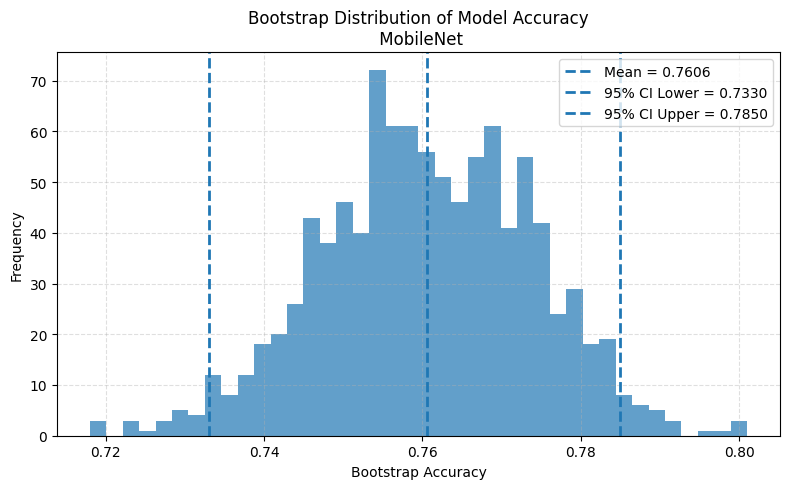

In [31]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score


def bootstrap_ci(y_true, y_pred, n_iterations=1000, confidence=0.95):

    scores = []

    n = len(y_true)

    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    for _ in range(n_iterations):

        indices = np.random.randint(
            0,
            n,
            n
        )

        score = accuracy_score(
            y_true[indices],
            y_pred[indices]
        )

        scores.append(score)

    scores = np.array(scores)

    lower = np.percentile(
        scores,
        (1-confidence)/2*100
    )

    upper = np.percentile(
        scores,
        (1+confidence)/2*100
    )

    return scores, np.mean(scores), lower, upper



# Run bootstrap
bootstrap_scores, mean_acc, lower, upper = bootstrap_ci(
    y_true,
    y_pred
)


print("\nBootstrap Accuracy CI:")
print(f"Mean Accuracy: {mean_acc:.4f}")
print(f"95% CI: [{lower:.4f}, {upper:.4f}]")


# ============================================================
# PLOT BOOTSTRAP DISTRIBUTION
# ============================================================

plt.figure(figsize=(8,5))

plt.hist(
    bootstrap_scores,
    bins=40,
    alpha=0.7
)

# Mean line
plt.axvline(
    mean_acc,
    linestyle="--",
    linewidth=2,
    label=f"Mean = {mean_acc:.4f}"
)

# CI lines
plt.axvline(
    lower,
    linestyle="--",
    linewidth=2,
    label=f"95% CI Lower = {lower:.4f}"
)

plt.axvline(
    upper,
    linestyle="--",
    linewidth=2,
    label=f"95% CI Upper = {upper:.4f}"
)


plt.xlabel("Bootstrap Accuracy")
plt.ylabel("Frequency")

plt.title(
    "Bootstrap Distribution of Model Accuracy\n MobileNet"
)

plt.legend()

plt.grid(
    linestyle="--",
    alpha=0.4
)

plt.tight_layout()
plt.show()

# **TTA**

TTA Accuracy: 0.7590


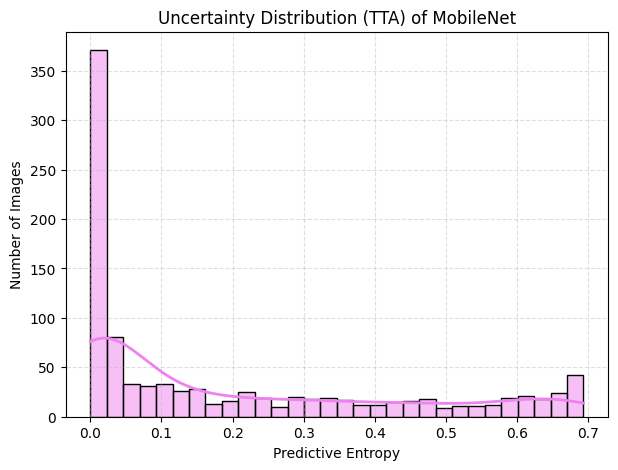

In [32]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras.applications.mobilenet import preprocess_input

# -----------------------------
# TTA parameters
# -----------------------------
tta_steps = 10
img_size = (224, 224)
batch_size = 32


def apply_strong(img):
    # Ensure RGB and resize
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, img_size)

    # Example strong augmentations for MixMatch
    if np.random.rand() > 0.5:
        img = cv2.flip(img, 1)  # horizontal flip
    factor = 0.9 + 0.2 * np.random.rand()  # brightness [0.9,1.1]
    img = np.clip(img * factor, 0, 255).astype(np.uint8)

    return img

# -----------------------------
# Prepare test images
# -----------------------------
image_paths = test_df['image_path'].tolist()
all_probs = []

for step in range(tta_steps):
    batch_images = []
    for path in image_paths:
        img = cv2.imread(path)
        img_aug = apply_strong(img)
        batch_images.append(img_aug)

    batch_images = np.stack(batch_images, axis=0)
    batch_images = preprocess_input(batch_images)  # MixMatch uses MobileNet preprocessing

    # Predict probabilities
    probs = model.predict(batch_images, batch_size=batch_size, verbose=0)
    all_probs.append(probs)

# -----------------------------
# Average predictions across TTA
# -----------------------------
y_prob_tta = np.mean(all_probs, axis=0)
y_pred_tta = np.argmax(y_prob_tta, axis=1)

# True labels
y_true = test_gen.classes

# Compute TTA accuracy
tta_acc = np.mean(y_pred_tta == y_true)
print(f"TTA Accuracy: {tta_acc:.4f}")

# -----------------------------
# Predictive entropy for uncertainty
# -----------------------------
entropy = -np.sum(y_prob_tta * np.log(y_prob_tta + 1e-8), axis=1)

# Plot histogram of predictive entropy
plt.figure(figsize=(7,5))
sns.histplot(entropy, bins=30, kde=True, color="violet",
             line_kws={"linewidth": 2, "color": "violet"})
plt.title("Uncertainty Distribution (TTA) of MobileNet")
plt.xlabel("Predictive Entropy")
plt.ylabel("Number of Images")
plt.grid(True, linestyle='--', alpha=0.4)
plt.show()

# **TTA Improvement Comparison Plot**

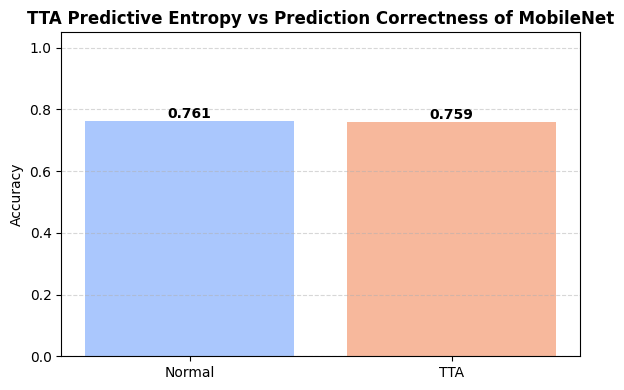

In [33]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

normal_acc = np.mean(y_pred == y_true)
tta_acc = np.mean(y_pred_tta == y_true)

accs = [normal_acc, tta_acc]
labels = ["Normal", "TTA"]

colors = sns.color_palette("coolwarm", 2)

plt.figure(figsize=(6,4))

bars = plt.bar(labels, accs, color=colors, linewidth=1.2)

# Add value labels on top
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2,
             height + 0.01,
             f"{height:.3f}",
             ha='center', fontsize=10, fontweight='bold')

plt.title("TTA Predictive Entropy vs Prediction Correctness of MobileNet",
          fontsize=12, fontweight='bold')

plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

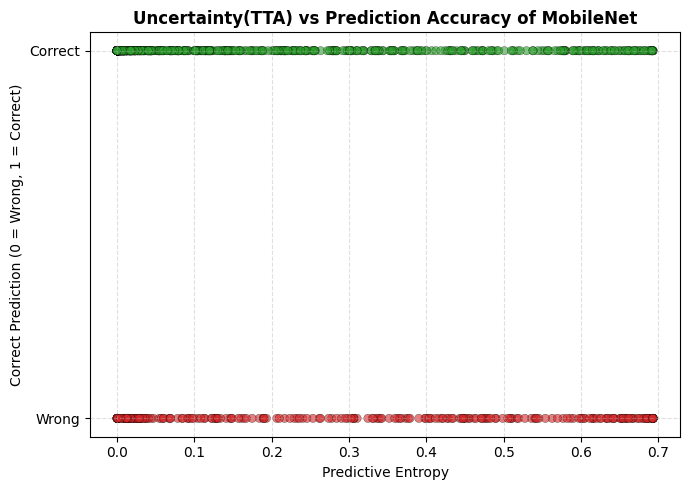

In [34]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

correct = (y_pred_tta == y_true)

plt.figure(figsize=(7,5))

# Color by correctness (very useful for analysis)
colors = np.where(correct, "#2ca02c", "#d62728")  # green = correct, red = wrong

plt.scatter(entropy, correct, c=colors, alpha=0.6, edgecolor='black', linewidth=0.3)

plt.title("Uncertainty(TTA) vs Prediction Accuracy of MobileNet",
          fontsize=12, fontweight='semibold')

plt.xlabel("Predictive Entropy")
plt.ylabel("Correct Prediction (0 = Wrong, 1 = Correct)")

plt.yticks([0, 1], ["Wrong", "Correct"])

plt.grid(axis='both', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

# **Prediction Confidence Distribution**

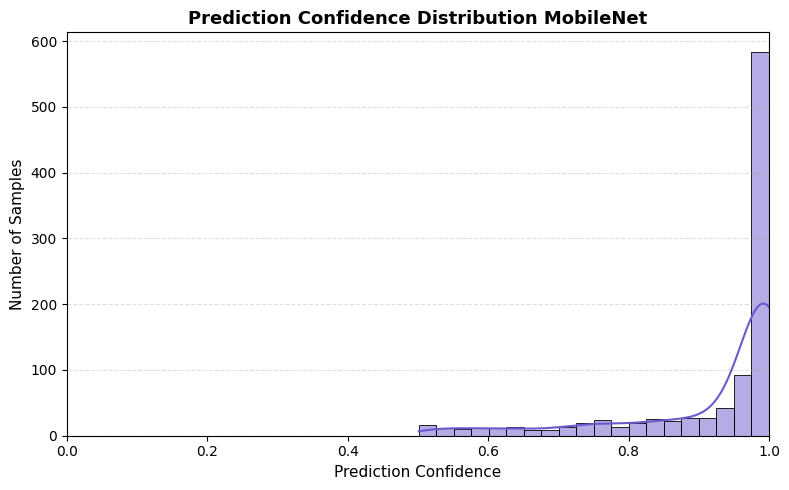

In [35]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

confidence = np.max(y_prob, axis=1)

plt.figure(figsize=(8,5))

# Histogram with KDE overlay for smooth distribution
sns.histplot(confidence,
             bins=20,
             kde=True,
             color="#6a5acd",
             edgecolor="black",
             linewidth=0.6)

# Styling
plt.title("Prediction Confidence Distribution MobileNet",
          fontsize=13, fontweight='bold')

plt.xlabel("Prediction Confidence", fontsize=11)
plt.ylabel("Number of Samples", fontsize=11)

plt.xlim(0, 1)
plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

# **ECE**

32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 65ms/step
Expected Calibration Error (ECE): 0.1719


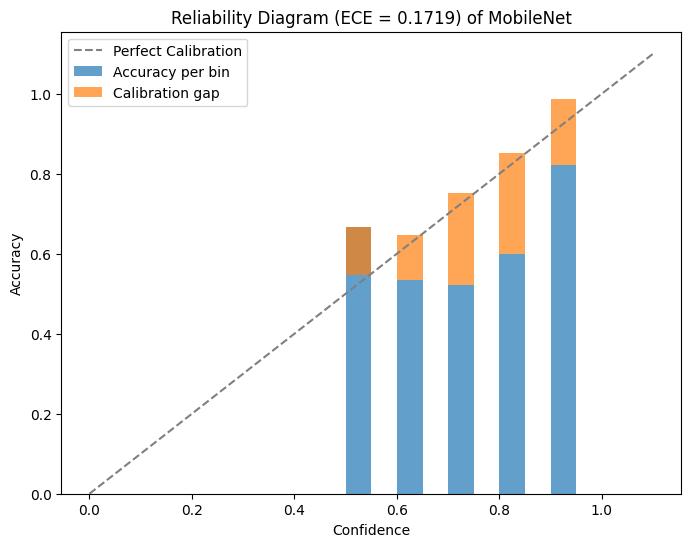

In [36]:
import numpy as np
import matplotlib.pyplot as plt

def compute_ece(probs, labels, n_bins=10):
    """
    Compute Expected Calibration Error (ECE)

    probs: array of shape (num_samples, num_classes), predicted probabilities
    labels: array of shape (num_samples,), true class indices
    n_bins: number of bins for calibration
    """
    labels = np.array(labels)  # ensure labels is a numpy array
    confidences = np.max(probs, axis=1)  # predicted probability of the predicted class
    predictions = np.argmax(probs, axis=1)

    bin_edges = np.linspace(0, 1, n_bins + 1)
    ece = 0.0
    bin_acc = []
    bin_conf = []
    bin_sizes = []

    for i in range(n_bins):
        lower, upper = bin_edges[i], bin_edges[i+1]
        mask = (confidences > lower) & (confidences <= upper)
        bin_size = np.sum(mask)

        if bin_size > 0:
            acc = np.mean((predictions[mask] == labels[mask]))
            conf = np.mean(confidences[mask])
            ece += (bin_size / len(labels)) * abs(acc - conf)
        else:
            acc, conf = 0, 0

        bin_acc.append(acc)
        bin_conf.append(conf)
        bin_sizes.append(bin_size)

    return ece, bin_acc, bin_conf, bin_sizes

# Convert predictions to probabilities if not already
y_probs = model.predict(test_gen)  # shape: (num_samples, num_classes)
y_true_array = np.array(test_gen.classes)  # convert to numpy array

# Compute ECE
ece, bin_acc, bin_conf, bin_sizes = compute_ece(y_probs, y_true_array, n_bins=10)
print(f"Expected Calibration Error (ECE): {ece:.4f}")

# Plot reliability diagram
plt.figure(figsize=(8,6))
plt.plot([0,1.1], [0,1.1], linestyle='--', color='gray', label='Perfect Calibration')
plt.bar(np.arange(10)/10 + 0.05/2, bin_acc, width=0.05, alpha=0.7, label='Accuracy per bin')
plt.bar(np.arange(10)/10 + 0.05/2, np.array(bin_conf)-np.array(bin_acc), bottom=bin_acc, width=0.05, alpha=0.7, label='Calibration gap')

plt.xlabel("Confidence")
plt.ylabel("Accuracy")
plt.title(f"Reliability Diagram (ECE = {ece:.4f}) of MobileNet")
plt.legend()
plt.show()

# **Grad-Cam**

In [37]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import cv2

# ============================================================
# FIND LAST CONV LAYER AUTOMATICALLY
# ============================================================
def get_last_conv_layer(model):
    # safer: check layer output tensor shape
    for layer in reversed(model.layers):
        try:
            if len(layer.output.shape) == 4:
                return layer.name
        except:
            continue
    return None

last_conv_layer_name = get_last_conv_layer(model)
print("Last Conv Layer:", last_conv_layer_name)


Last Conv Layer: conv_pw_13_relu



Grad-CAM for class 0: /kaggle/working/train/benign/40X_SOB_B_F-14-25197-40-038.png

Grad-CAM for class 0: /kaggle/working/train/benign/40X_SOB_B_F-14-25197-40-038.png
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s
Predicted class id: 1 | Probability: 0.996
True class: 0


/usr/local/lib/python3.12/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: [['keras_tensor']]
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


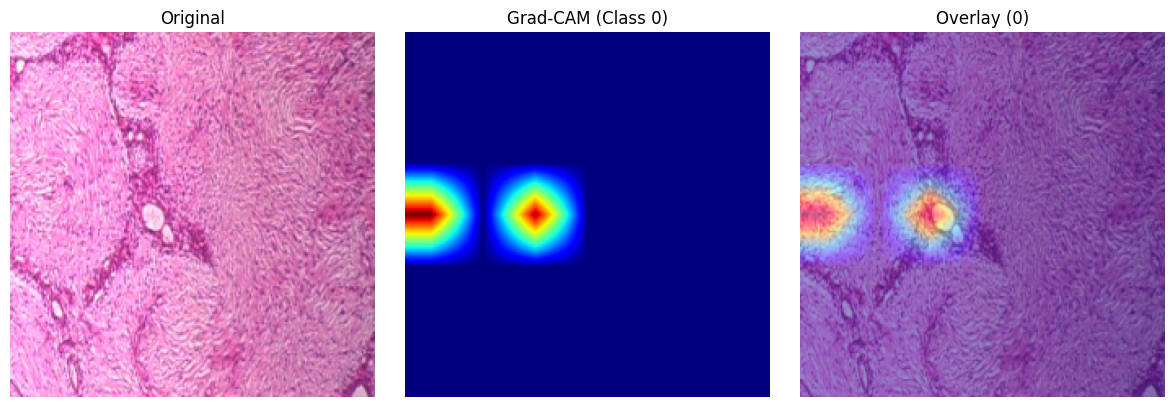


Grad-CAM for class 1: /kaggle/working/train/malignant/400X_SOB_M_DC-14-11031-400-007.png

Grad-CAM for class 1: /kaggle/working/train/malignant/400X_SOB_M_DC-14-11031-400-007.png
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s
Predicted class id: 1 | Probability: 0.997
True class: 1


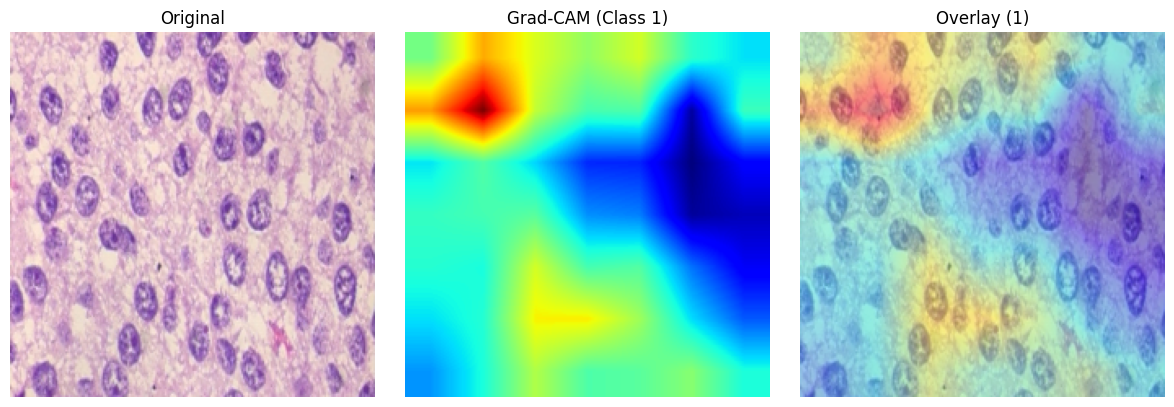

In [38]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import cv2


# ============================================================
# GRAD-CAM HEATMAP FUNCTION (FIXED)
# ============================================================
def make_gradcam_heatmap(img_array, model, last_conv_layer_name, class_index):

    grad_model = tf.keras.models.Model(
        [model.inputs],
        [
            model.get_layer(last_conv_layer_name).output,
            model.output
        ]
    )

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)

        # ✅ FIX: safe TensorFlow indexing
        class_channel = tf.gather(predictions, class_index, axis=1)

    # gradients of target class w.r.t conv outputs
    grads = tape.gradient(class_channel, conv_outputs)

    # global average pooling of gradients
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    conv_outputs = conv_outputs[0]

    # weight feature maps
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    # normalize heatmap
    heatmap = tf.maximum(heatmap, 0)
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)

    return heatmap.numpy()


# ============================================================
# DISPLAY GRAD-CAM FUNCTION
# ============================================================
def display_gradcam(
    img_path,
    model,
    last_conv_layer_name,
    class_index,
    class_name=None,
    alpha=0.4,
    img_size=(224, 224)
):

    # -------------------------
    # Load image
    # -------------------------
    img = tf.keras.utils.load_img(img_path, target_size=img_size)
    img_array = tf.keras.utils.img_to_array(img)

    # -------------------------
    # Preprocess (MobileNetV3)
    # -------------------------
    img_array_exp = np.expand_dims(img_array, axis=0)
    img_array_exp = preprocess_input(img_array_exp)

    # -------------------------
    # Prediction
    # -------------------------
    preds = model.predict(img_array_exp, verbose=0)
    pred_idx = np.argmax(preds[0])
    pred_prob = np.max(preds[0])

    print(f"\nGrad-CAM for class {class_index}: {img_path}")
    print("1/1 ━━━━━━━━━━━━━━━━━━━━ 0s")
    print(f"Predicted class id: {pred_idx} | Probability: {pred_prob:.3f}")

    if class_name is not None:
        print(f"True class: {class_name}")

    # -------------------------
    # Grad-CAM heatmap
    # -------------------------
    heatmap = make_gradcam_heatmap(
        img_array_exp,
        model,
        last_conv_layer_name,
        class_index
    )

    heatmap_resized = cv2.resize(heatmap, img_size)

    # -------------------------
    # Heatmap overlay
    # -------------------------
    heatmap_uint8 = np.uint8(255 * heatmap_resized)
    heatmap_color = cv2.applyColorMap(heatmap_uint8, cv2.COLORMAP_JET)

    original_img = cv2.imread(img_path)
    original_img = cv2.resize(original_img, img_size)

    overlay_img = cv2.addWeighted(
        original_img,
        1 - alpha,
        heatmap_color,
        alpha,
        0
    )

    # -------------------------
    # Visualization
    # -------------------------
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 3, 1)
    plt.imshow(cv2.cvtColor(original_img, cv2.COLOR_BGR2RGB))
    plt.title("Original")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(heatmap_resized, cmap="jet")
    plt.title(f"Grad-CAM (Class {class_index})")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(cv2.cvtColor(overlay_img, cv2.COLOR_BGR2RGB))

    title = "Overlay"
    if class_name:
        title += f" ({class_name})"

    plt.title(title)
    plt.axis("off")

    plt.tight_layout()
    plt.show()


# ============================================================
# RUN FOR MULTIPLE CLASSES
# ============================================================
class_ids = test_df['label_num'].unique()

for cls in class_ids:
    img_path = test_df[test_df['label_num'] == cls]['image_path'].iloc[6]

    print(f"\nGrad-CAM for class {cls}: {img_path}")

    display_gradcam(
        img_path=img_path,
        model=model,
        last_conv_layer_name=last_conv_layer_name,
        class_index=int(cls),
        class_name=str(cls)
    )